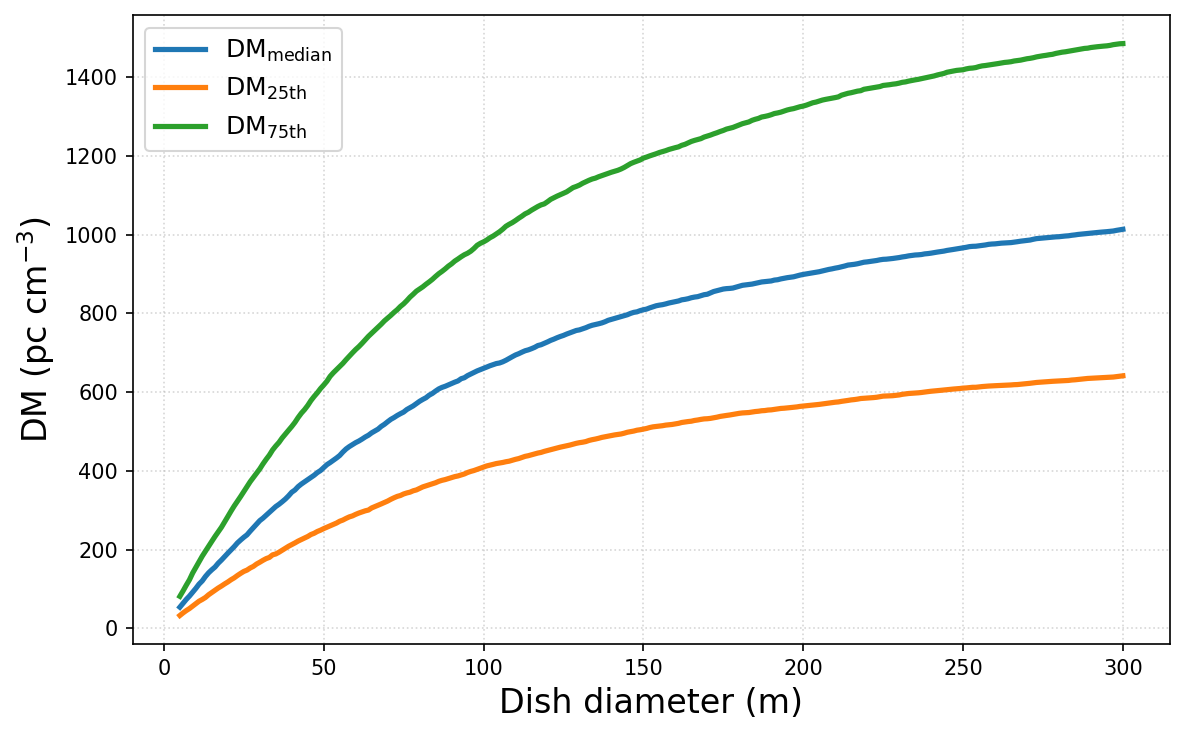

In [1]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt

# Load the CSV file
csv_file = "/home/thsu/FRB_population/DM_percentiles_vs_dish_size.csv"
df = pd.read_csv(csv_file)

# Sort by dish_size to ensure the lines are plotted in order
df = df.sort_values("dish_size")

# Create the figure
fig, ax = plt.subplots(figsize=(8, 5), dpi=150)

# Plot the median DM and the 25th/75th percentiles (lines only, no markers)
ax.plot(df["dish_size"], df["DM_median"], linestyle="-", label="DM$_{\\rm median}$", linewidth=2.5)
ax.plot(df["dish_size"], df["DM_25"], linestyle="-", label="DM$_{\\rm 25th}$", linewidth=2.5)
ax.plot(df["dish_size"], df["DM_75"], linestyle="-", label="DM$_{\\rm 75th}$", linewidth=2.5)

# Labels and formatting
ax.set_xlabel("Dish diameter (m)", fontsize=16)
ax.set_ylabel(r"DM (pc cm$^{-3}$)", fontsize=16)
ax.legend(fontsize=12)
ax.grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()

# Optional: save the figure
# fig.savefig("DM_vs_dish_size.png", dpi=300, bbox_inches="tight")

Breaks from Euclidean at D ≈ 26.0 m


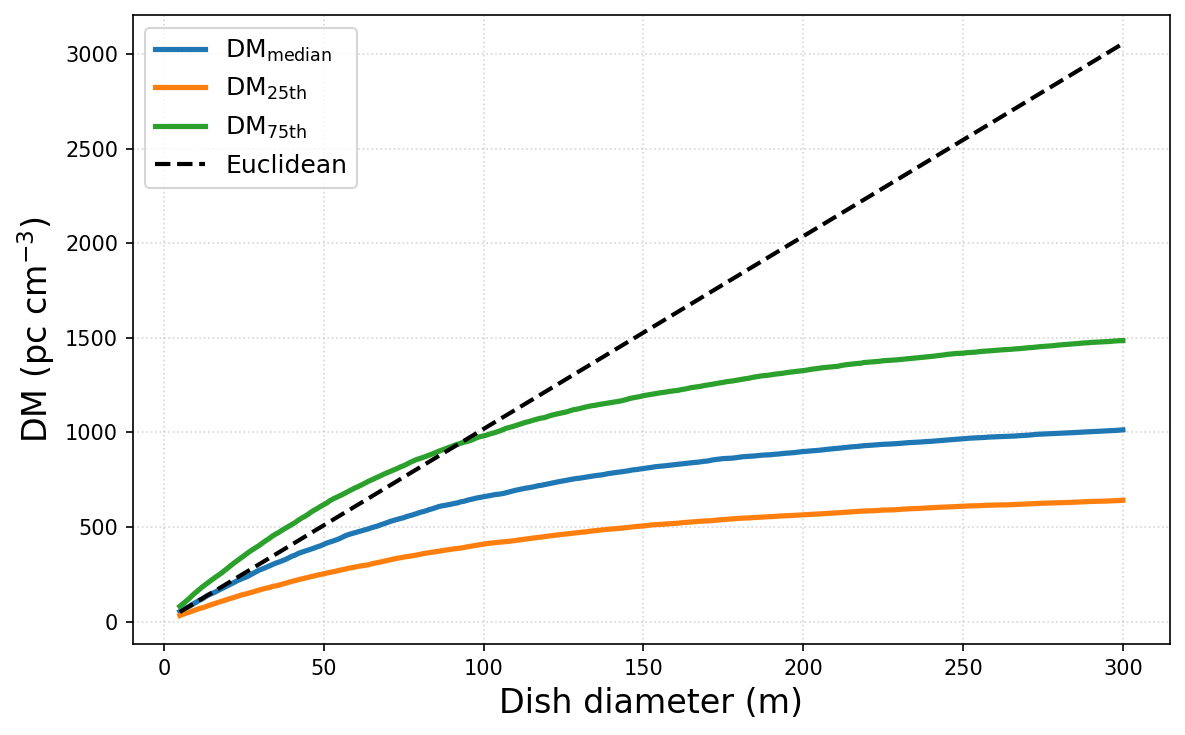

In [3]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

csv_file = "/home/thsu/FRB_population/DM_percentiles_vs_dish_size.csv"
df = pd.read_csv(csv_file).sort_values("dish_size")

D  = df["dish_size"].to_numpy()
DM = df["DM_median"].to_numpy()

# Euclidean: DM = k * D, with k from the small dishes (D < 15 m)
small = D < 15
k = np.sum(D[small] * DM[small]) / np.sum(D[small] ** 2)
D_line = np.linspace(D.min(), D.max(), 200)

# Where does the median first drop >10% below the Euclidean line?
below = (DM < 0.9 * k * D) & ~small
if below.any():
    print(f"Breaks from Euclidean at D ≈ {D[below][0]:.1f} m")

fig, ax = plt.subplots(figsize=(8, 5), dpi=150)
ax.plot(D, DM, lw=2.5, label="DM$_{\\rm median}$")
ax.plot(D, df["DM_25"], lw=2.5, label="DM$_{\\rm 25th}$")
ax.plot(D, df["DM_75"], lw=2.5, label="DM$_{\\rm 75th}$")
ax.plot(D_line, k * D_line, "k--", lw=2, label="Euclidean")

ax.set_xlabel("Dish diameter (m)", fontsize=16)
ax.set_ylabel(r"DM (pc cm$^{-3}$)", fontsize=16)
ax.legend(fontsize=12)
ax.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()